# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Yoga Putra Pratama
- **Email:** ds002b6y1992@student.devacademy.id
- **ID Dicoding:** ds002b6y1992

## Menentukan Pertanyaan Bisnis

**Konteks.** Dataset yang dipakai adalah *E-Commerce Public Dataset* milik Olist, marketplace asal Brasil. Data mencakup pesanan, item pesanan, pelanggan, produk, ulasan, dan lokasi. Seluruh nilai uang dalam **Brazilian Real (R$)**. Dalam proyek ini, **revenue** didefinisikan sebagai jumlah kolom `price` (harga produk, tanpa ongkos kirim) dari pesanan berstatus *delivered*.

**Pertanyaan bisnis (SMART):**

1. **Kategori produk** apa saja yang menjadi 10 penyumbang revenue tertinggi dan 10 terendah pada pesanan *delivered* periode **Januari 2017 – Agustus 2018**, dan berapa persen kontribusi 10 kategori teratas terhadap total revenue?
   - *Specific*: fokus pada revenue per kategori produk. *Measurable*: total revenue (R$) dan persentase kontribusi. *Action-oriented*: menentukan kategori prioritas untuk stok, promosi, dan akuisisi seller. *Relevant*: keputusan merchandising adalah inti bisnis marketplace. *Time-bound*: Jan 2017 – Agu 2018.
2. Bagaimana **tren jumlah pesanan dan revenue bulanan** (Month-over-Month) pada periode **Januari 2017 – Agustus 2018**: bulan mana yang tumbuh dan turun paling tajam, dan seberapa besar lonjakan puncaknya?
   - *Measurable*: jumlah pesanan, revenue, dan % pertumbuhan MoM. *Action-oriented*: perencanaan kampanye, stok, dan kapasitas logistik menjelang bulan puncak. *Time-bound*: per bulan, Jan 2017 – Agu 2018.
3. Berapa **selisih rata-rata review score** antara pesanan yang tiba **terlambat** dan yang **tepat waktu** pada periode **Januari 2017 – Agustus 2018**, dan di **state** mana persentase pesanan terlambat paling tinggi (state dengan minimal 300 pesanan)?
   - *Measurable*: selisih skor (skala 1–5) dan % pesanan terlambat. *Action-oriented*: menentukan wilayah yang perlu perbaikan logistik lebih dulu. *Relevant*: kepuasan pelanggan menentukan retensi.
4. Bagaimana **sebaran pelanggan unik berdasarkan segmen RFM** (snapshot 1 September 2018, data Jan 2017 – Agu 2018), dan segmen mana yang menyumbang revenue terbesar?
   - *Measurable*: jumlah pelanggan dan persentase revenue per segmen. *Action-oriented*: menentukan segmen yang diprioritaskan untuk program retensi dan reaktivasi.

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

# Palet & gaya visualisasi yang konsisten di seluruh notebook:
# satu warna aksen untuk hal yang ingin disorot, abu-abu untuk konteks, merah untuk peringatan.
ACCENT, GREY, ALERT = '#1f6f8b', '#c5cbd1', '#d1495b'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.labelsize': 10,
    'figure.dpi': 100,
})

def brl(x):
    """Format angka sebagai nilai Real Brasil, mis. R$ 1,229,558."""
    return f'R$ {x:,.0f}'

## Data Wrangling

### Gathering Data
Tujuh tabel yang relevan dengan pertanyaan bisnis dimuat ke DataFrame: `orders`, `order_items`, `customers`, `products`, `product_category_name_translation`, `order_reviews`, dan `geolocation`. Tabel `order_payments` dan `sellers` tidak dibutuhkan karena revenue dihitung dari harga item, bukan dari data pembayaran, dan tidak ada pertanyaan yang menyangkut seller. Berkas CSV dibaca dengan `encoding='utf-8-sig'` karena tabel terjemahan kategori memiliki karakter BOM di awal berkas.

In [2]:
DATA_DIR = 'data'

def load(nama_file):
    return pd.read_csv(f'{DATA_DIR}/{nama_file}', encoding='utf-8-sig')

orders_df = load('orders_dataset.csv')
order_items_df = load('order_items_dataset.csv')
customers_df = load('customers_dataset.csv')
products_df = load('products_dataset.csv')
category_translation_df = load('product_category_name_translation.csv')
reviews_df = load('order_reviews_dataset.csv')
geolocation_df = load('geolocation_dataset.csv')

tables = {
    'orders': orders_df, 'order_items': order_items_df, 'customers': customers_df,
    'products': products_df, 'category_translation': category_translation_df,
    'order_reviews': reviews_df, 'geolocation': geolocation_df,
}
for nama, d in tables.items():
    print(f'[{nama}] {d.shape[0]:,} baris x {d.shape[1]} kolom')
display(orders_df.head(3))
display(order_items_df.head(3))
display(customers_df.head(3))

[orders] 99,441 baris x 8 kolom
[order_items] 112,650 baris x 7 kolom
[customers] 99,441 baris x 5 kolom
[products] 32,951 baris x 9 kolom
[category_translation] 71 baris x 2 kolom
[order_reviews] 99,224 baris x 7 kolom
[geolocation] 1,000,163 baris x 5 kolom


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


**Insight (Gathering Data):**
- `orders` memiliki 99.441 pesanan dan menjadi tabel pusat: `order_items` terhubung lewat `order_id`, `customers` lewat `customer_id`, dan `order_reviews` lewat `order_id`.
- `order_items` (112.650 baris) adalah tingkat paling rinci: satu pesanan bisa berisi beberapa item. Konsekuensinya, setiap metrik tingkat-pesanan (review, keterlambatan, jumlah pesanan) nanti harus dihitung ulang tanpa duplikasi `order_id`.
- `customers` punya dua ID: `customer_id` (unik per pesanan) dan `customer_unique_id` (identitas pelanggan sebenarnya). Analisis RFM harus memakai `customer_unique_id`.
- `geolocation` berukuran besar (sekitar 1 juta baris) dan kuat dugaan berisi banyak titik koordinat per kode pos.

### Assessing Data
Kualitas setiap tabel dinilai dari ukuran, missing value, duplikasi, tipe data, serta validitas dan konsistensi nilai.

In [3]:
ringkasan = pd.DataFrame({
    'tabel': list(tables.keys()),
    'jumlah_baris': [d.shape[0] for d in tables.values()],
    'jumlah_kolom': [d.shape[1] for d in tables.values()],
    'total_missing': [int(d.isna().sum().sum()) for d in tables.values()],
    'baris_duplikat': [int(d.duplicated().sum()) for d in tables.values()],
})
ringkasan

,tabel,jumlah_baris,jumlah_kolom,total_missing,baris_duplikat
0,orders,99441,8,4908,0
1,order_items,112650,7,0,0
2,customers,99441,5,0,0
3,products,32951,9,2448,0
4,category_translation,71,2,0,0
5,order_reviews,99224,7,145903,0
6,geolocation,1000163,5,0,261831


In [4]:
# Rincian missing value per kolom (hanya kolom yang memiliki missing)
for nama, d in tables.items():
    miss = d.isna().sum()
    miss = miss[miss > 0]
    if len(miss):
        print(f'[{nama}]')
        print(miss.to_string())
        print()

[orders]
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

[products]
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

[order_reviews]
review_comment_title      87656
review_comment_message    58247



In [5]:
# Tipe data tabel orders: kolom tanggal masih bertipe object (string)
print(orders_df.dtypes.to_string())
print()

# Sebaran status pesanan
print(orders_df['order_status'].value_counts().to_string())

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2


In [6]:
# Cakupan waktu pesanan per bulan
ts = orders_df.copy()
for kolom in ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
              'order_delivered_customer_date', 'order_estimated_delivery_date']:
    ts[kolom] = pd.to_datetime(ts[kolom])

pesanan_per_bulan = ts.groupby(ts['order_purchase_timestamp'].dt.to_period('M')).size()
print(pesanan_per_bulan.to_string())

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


In [7]:
# Logika data pesanan yang tidak konsisten / tidak valid
print('Delivered tetapi tanggal tiba di pelanggan kosong :',
      ((ts['order_status'] == 'delivered') & ts['order_delivered_customer_date'].isna()).sum())
print('Tanggal serah ke kurir SETELAH tanggal tiba       :',
      (ts['order_delivered_carrier_date'] > ts['order_delivered_customer_date']).sum())
print('Status bukan delivered tapi punya tanggal tiba    :',
      ((ts['order_status'] != 'delivered') & ts['order_delivered_customer_date'].notna()).sum())

Delivered tetapi tanggal tiba di pelanggan kosong : 8
Tanggal serah ke kurir SETELAH tanggal tiba       : 23
Status bukan delivered tapi punya tanggal tiba    : 6


In [8]:
# Duplikasi ulasan: satu pesanan seharusnya hanya punya satu ulasan
dup_order = reviews_df['order_id'].duplicated().sum()
print('order_id dengan lebih dari satu ulasan (baris berlebih):', dup_order)
contoh = reviews_df[reviews_df['order_id'].duplicated(keep=False)].sort_values('order_id').head(4)
contoh[['order_id', 'review_id', 'review_score', 'review_answer_timestamp']]

order_id dengan lebih dari satu ulasan (baris berlebih): 551


,order_id,review_id,review_score,review_answer_timestamp
25612,0035246a40f520710769010f752e7507,89a02c45c340aeeb1354a24e7d4b2c1e,5,2017-08-30 01:59:12
22423,0035246a40f520710769010f752e7507,2a74b0559eb58fc1ff842ecc999594cb,5,2017-08-29 21:45:57
22779,013056cfe49763c6f66bda03396c5ee3,ab30810c29da5da8045216f0f62652a2,5,2018-02-23 12:12:30
68633,013056cfe49763c6f66bda03396c5ee3,73413b847f63e02bc752b364f6d05ee9,4,2018-03-05 17:02:00


In [9]:
# Produk: kategori kosong dan kategori yang tidak punya terjemahan
print('Produk tanpa kategori:', products_df['product_category_name'].isna().sum())
tanpa_terjemahan = set(products_df['product_category_name'].dropna()) - set(category_translation_df['product_category_name'])
print('Kategori tanpa terjemahan bahasa Inggris:', tanpa_terjemahan)

Produk tanpa kategori: 610
Kategori tanpa terjemahan bahasa Inggris: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


In [10]:
# Geolocation: duplikasi baris, koordinat di luar wilayah Brasil, dan penulisan nama kota tidak konsisten
print('Baris duplikat:', geolocation_df.duplicated().sum(), f'({geolocation_df.duplicated().mean():.1%} dari seluruh baris)')

# Brasil kira-kira berada di lat -34 s/d 6 dan lng -74 s/d -34
di_luar = ~(geolocation_df['geolocation_lat'].between(-34, 6) & geolocation_df['geolocation_lng'].between(-74, -34))
print('Titik koordinat di luar Brasil:', di_luar.sum())
print(geolocation_df.loc[di_luar, ['geolocation_lat', 'geolocation_lng', 'geolocation_state']].head(3).to_string())

# Ejaan inkonsisten untuk kota Sao Paulo
sp = geolocation_df[geolocation_df['geolocation_city'].str.contains('paulo') & (geolocation_df['geolocation_state'] == 'SP')]
print()
print(sp['geolocation_city'].value_counts().head(5).to_string())

Baris duplikat: 261831 (26.2% dari seluruh baris)
Titik koordinat di luar Brasil: 42
        geolocation_lat  geolocation_lng geolocation_state
387565        28.008978       -15.536867                SP
513631        41.614052        -8.411675                RJ
513643       -34.586422       -58.732101                RJ

geolocation_city
sao paulo         135799
são paulo          24917
paulo de faria        56
sãopaulo               2
sa£o paulo             1


In [11]:
# Outlier harga & ongkir (metode IQR)
for kolom in ['price', 'freight_value']:
    q1, q3 = order_items_df[kolom].quantile([0.25, 0.75])
    batas = q3 + 1.5 * (q3 - q1)
    n_out = (order_items_df[kolom] > batas).sum()
    print(f'{kolom}: batas atas IQR = {batas:,.2f} | outlier = {n_out:,} ({n_out/len(order_items_df):.1%}) | maks = {order_items_df[kolom].max():,.2f}')

price: batas atas IQR = 277.40 | outlier = 8,427 (7.5%) | maks = 6,735.00
freight_value: batas atas IQR = 33.25 | outlier = 11,613 (10.3%) | maks = 409.68


**Insight (Assessing Data)** — masalah yang ditemukan dan tindakan pada tahap *cleaning*:

| # | Jenis masalah | Temuan | Tindakan |
|---|---|---|---|
| 1 | **Missing value** | `order_delivered_customer_date` kosong pada 2.965 pesanan (8 di antaranya berstatus *delivered*); 610 produk tanpa kategori; 2 produk tanpa dimensi | Hanya pesanan *delivered* dengan tanggal tiba terisi yang dipakai; kategori kosong diisi `unknown` |
| 2 | **Duplicate data** | `geolocation` memiliki 261.831 baris duplikat; 551 `order_id` memiliki lebih dari satu ulasan | Hapus duplikat geolokasi dan agregasi ke level kode pos; simpan ulasan terbaru per pesanan |
| 3 | **Invalid value** | 42 titik koordinat berada di luar Brasil (mis. lat 45, lng 121) | Buang titik di luar bounding box Brasil |
| 4 | **Inaccurate value** | 23 pesanan memiliki tanggal serah ke kurir setelah tanggal tiba | Tidak memengaruhi metrik yang dipakai (hanya tanggal pembelian dan tiba yang dipakai); dicatat sebagai keterbatasan |
| 5 | **Inconsistent value** | Dua kategori produk tidak ada di tabel terjemahan; kota São Paulo tertulis `sao paulo`, `são paulo`, `sa£o paulo`, dst. | Tambahkan terjemahan manual; geolokasi diagregasi per kode pos sehingga ejaan kota tidak dipakai |
| 6 | **Tipe data** | Kolom tanggal bertipe `object` | Konversi ke `datetime` |
| 7 | **Cakupan waktu** | 2016 hanya berisi 329 pesanan dan Sep–Okt 2018 hanya 20 pesanan (bulan tidak lengkap) | Batasi analisis pada **Januari 2017 – Agustus 2018** |
| 8 | **Outlier** | Harga maksimum R$ 6.735 dan ongkir maksimum R$ 409 jauh di atas batas IQR | **Dipertahankan**: nilai tersebut masuk akal untuk barang bernilai tinggi dan bukan kesalahan input |

### Cleaning Data

**1. Konversi tipe data tanggal**

In [12]:
kolom_tanggal = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                 'order_delivered_customer_date', 'order_estimated_delivery_date']
for kolom in kolom_tanggal:
    orders_df[kolom] = pd.to_datetime(orders_df[kolom])

reviews_df['review_answer_timestamp'] = pd.to_datetime(reviews_df['review_answer_timestamp'])
orders_df[kolom_tanggal].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

**2. Menyaring pesanan:** hanya berstatus *delivered*, tanggal tiba terisi, dan terjadi pada Januari 2017 – Agustus 2018

In [13]:
n_awal = len(orders_df)
orders_clean = orders_df[
    (orders_df['order_status'] == 'delivered')
    & orders_df['order_delivered_customer_date'].notna()
    & (orders_df['order_purchase_timestamp'] >= '2017-01-01')
    & (orders_df['order_purchase_timestamp'] < '2018-09-01')
].copy()
print(f'Pesanan sebelum disaring : {n_awal:,}')
print(f'Pesanan setelah disaring : {len(orders_clean):,}')
print(orders_clean['order_purchase_timestamp'].agg(['min', 'max']).to_string())

Pesanan sebelum disaring : 99,441
Pesanan setelah disaring : 96,203
min   2017-01-05 11:56:06
max   2018-08-29 15:00:37


**3. Ulasan ganda:** untuk pesanan dengan lebih dari satu ulasan, simpan ulasan yang paling akhir dijawab

In [14]:
n_awal = len(reviews_df)
reviews_clean = (reviews_df.sort_values('review_answer_timestamp')
                 .drop_duplicates(subset='order_id', keep='last'))
print(f'Ulasan sebelum: {n_awal:,} | sesudah: {len(reviews_clean):,} | order_id duplikat tersisa: {reviews_clean["order_id"].duplicated().sum()}')

Ulasan sebelum: 99,224 | sesudah: 98,673 | order_id duplikat tersisa: 0


**4. Kategori produk:** tambahkan terjemahan yang hilang, lalu isi kategori kosong dengan `unknown`

In [15]:
terjemahan_tambahan = pd.DataFrame({
    'product_category_name': ['portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'],
    'product_category_name_english': ['portable_kitchen_food_preparers', 'pc_gamer'],
})
translation_clean = pd.concat([category_translation_df, terjemahan_tambahan], ignore_index=True)

products_clean = products_df.merge(translation_clean, on='product_category_name', how='left')
products_clean['product_category'] = products_clean['product_category_name_english'].fillna('unknown')
print('Produk dengan kategori unknown:', (products_clean['product_category'] == 'unknown').sum())
products_clean[['product_id', 'product_category']].head()

Produk dengan kategori unknown: 610


,product_id,product_category
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,art
2,96bd76ec8810374ed1b65e291975717f,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,baby
4,9dc1a7de274444849c219cff195d0b71,housewares


**5. Geolokasi:** hapus duplikat, buang koordinat di luar Brasil, lalu ambil rata-rata koordinat per kode pos

In [16]:
n_awal = len(geolocation_df)
geo_clean = geolocation_df.drop_duplicates()
geo_clean = geo_clean[
    geo_clean['geolocation_lat'].between(-34, 6) & geo_clean['geolocation_lng'].between(-74, -34)
]
geo_zip = (geo_clean.groupby('geolocation_zip_code_prefix', as_index=False)
           .agg(customer_lat=('geolocation_lat', 'mean'), customer_lng=('geolocation_lng', 'mean'))
           .rename(columns={'geolocation_zip_code_prefix': 'zip_code_prefix'}))
print(f'Baris geolokasi awal: {n_awal:,} -> setelah dibersihkan: {len(geo_clean):,} -> kode pos unik: {len(geo_zip):,}')

Baris geolokasi awal: 1,000,163 -> setelah dibersihkan: 738,299 -> kode pos unik: 19,010


**6. Menggabungkan tabel** menjadi satu DataFrame tingkat item pesanan, lalu menurunkan kolom keterlambatan.

Definisi keterlambatan: selisih hari antara **tanggal** tiba aktual dan **tanggal** estimasi tiba. Pesanan dinyatakan terlambat jika `delay_days > 0`. Perbandingan dilakukan pada level tanggal karena estimasi tiba selalu bernilai jam 00:00.

In [17]:
all_df = (
    order_items_df
    .merge(orders_clean[['order_id', 'customer_id', 'order_purchase_timestamp',
                         'order_delivered_customer_date', 'order_estimated_delivery_date']],
           on='order_id', how='inner')
    .merge(customers_df[['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_state']],
           on='customer_id', how='left')
    .merge(products_clean[['product_id', 'product_category']], on='product_id', how='left')
    .merge(reviews_clean[['order_id', 'review_score']], on='order_id', how='left')
    .merge(geo_zip, left_on='customer_zip_code_prefix', right_on='zip_code_prefix', how='left')
)
all_df['product_category'] = all_df['product_category'].fillna('unknown')

# Pastikan penggabungan tidak menggandakan baris
assert len(all_df) == order_items_df['order_id'].isin(orders_clean['order_id']).sum()

# Kolom turunan
all_df['delay_days'] = (all_df['order_delivered_customer_date'].dt.normalize()
                        - all_df['order_estimated_delivery_date'].dt.normalize()).dt.days
all_df['is_late'] = all_df['delay_days'] > 0
all_df['purchase_month'] = all_df['order_purchase_timestamp'].dt.to_period('M').astype(str)

print(f'Baris item: {len(all_df):,} | pesanan unik: {all_df["order_id"].nunique():,} | pelanggan unik: {all_df["customer_unique_id"].nunique():,}')
print('Missing review_score :', f'{all_df["review_score"].isna().mean():.2%}')
print('Missing koordinat    :', f'{all_df["customer_lat"].isna().mean():.2%}')
all_df.head(3)

Baris item: 109,872 | pesanan unik: 96,203 | pelanggan unik: 93,096
Missing review_score : 0.75%
Missing koordinat    : 0.26%


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_state,product_category,review_score,zip_code_prefix,customer_lat,customer_lng,delay_days,is_late,purchase_month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,28013,RJ,cool_stuff,5.0,28013.0,-21.763186,-41.310265,-9,False,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,15775,SP,pet_shop,4.0,15775.0,-20.222506,-50.898951,-3,False,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,35661,MG,furniture_decor,5.0,35661.0,-19.869998,-44.593059,-14,False,2018-01


In [18]:
# Menyimpan data akhir untuk dashboard (kolom seperlunya agar berkas ringan)
main_data = all_df[['order_id', 'customer_unique_id', 'customer_state', 'order_purchase_timestamp',
                    'product_category', 'price', 'freight_value', 'review_score',
                    'delay_days', 'is_late', 'customer_lat', 'customer_lng']].copy()
main_data['purchase_date'] = main_data['order_purchase_timestamp'].dt.strftime('%Y-%m-%d')
main_data = main_data.drop(columns='order_purchase_timestamp')
main_data[['customer_lat', 'customer_lng']] = main_data[['customer_lat', 'customer_lng']].round(4)
main_data = main_data[['order_id', 'customer_unique_id', 'customer_state', 'purchase_date', 'product_category',
                       'price', 'freight_value', 'review_score', 'delay_days', 'is_late',
                       'customer_lat', 'customer_lng']]
main_data.to_csv('dashboard/main_data.csv', index=False)
print(f'main_data.csv tersimpan: {main_data.shape[0]:,} baris x {main_data.shape[1]} kolom')

main_data.csv tersimpan: 109,872 baris x 12 kolom


**Insight (Cleaning Data):**
- Dari 99.441 pesanan, tersisa **96.203 pesanan *delivered*** (109.872 item) pada periode Jan 2017 – Agu 2018 yang siap dianalisis. Pesanan batal, belum terkirim, atau tanpa tanggal tiba dikeluarkan agar revenue dan keterlambatan hanya dihitung dari transaksi yang benar-benar selesai.
- Penggabungan tabel terbukti tidak menggandakan baris (dicek dengan `assert`), sehingga total revenue aman dihitung dari tingkat item.
- Hanya sekitar 0,7% item tanpa review score dan 0,3% tanpa koordinat, sehingga dampaknya kecil terhadap analisis.
- Data geolokasi menyusut dari sekitar 1 juta baris menjadi satu koordinat rata-rata per kode pos, cukup untuk analisis peta level state.

## Exploratory Data Analysis (EDA)

### Eksplorasi umum

In [19]:
all_df[['price', 'freight_value', 'review_score', 'delay_days']].describe().round(2)

,price,freight_value,review_score,delay_days
count,109872.00,109872.00,109049.00,109872.00
mean,119.96,19.95,4.08,-11.96
std,182.35,15.70,1.35,10.06
min,0.85,0.00,1.00,-147.00
25%,39.90,13.08,4.00,-17.00
50%,74.90,16.26,5.00,-13.00
75%,134.04,21.15,5.00,-7.00
max,6735.00,409.68,5.00,188.00


In [20]:
order_df = all_df.drop_duplicates('order_id').copy()   # data tingkat pesanan (1 baris = 1 pesanan)
print('Distribusi review score (% pesanan):')
print((order_df['review_score'].value_counts(normalize=True).sort_index() * 100).round(1).to_string())
print()
print(f'Rata-rata review score        : {order_df["review_score"].mean():.2f}')
print(f'Persentase pesanan terlambat  : {order_df["is_late"].mean():.1%}')
print(f'Total revenue (jumlah price)  : {brl(all_df["price"].sum())}')

Distribusi review score (% pesanan):
review_score
1.0     9.7
2.0     3.1
3.0     8.3
4.0    19.7
5.0    59.2

Rata-rata review score        : 4.16
Persentase pesanan terlambat  : 6.8%
Total revenue (jumlah price)  : R$ 13,179,778


### Pertanyaan 1: Revenue per kategori produk

In [21]:
category_stats = (all_df.groupby('product_category')
                  .agg(revenue=('price', 'sum'), items_sold=('order_item_id', 'count'), orders=('order_id', 'nunique'))
                  .sort_values('revenue', ascending=False))
total_revenue = all_df['price'].sum()
category_stats['share_pct'] = category_stats['revenue'] / total_revenue * 100

# Peringkat tidak menyertakan kategori 'unknown' (produk tanpa kategori)
category_rank = category_stats.drop(index='unknown', errors='ignore')
print('Jumlah kategori:', len(category_rank))
print('\n10 kategori revenue tertinggi:')
display(category_rank.head(10).round(2))
print('\n10 kategori revenue terendah:')
display(category_rank.tail(10).round(2))

top10_share = category_rank.head(10)['revenue'].sum() / total_revenue * 100
top3_share = category_rank.head(3)['revenue'].sum() / total_revenue * 100
bottom10_share = category_rank.tail(10)['revenue'].sum() / total_revenue * 100
print(f'\nKontribusi top-10 kategori terhadap total revenue : {top10_share:.1f}%')
print(f'Kontribusi top-3 kategori                         : {top3_share:.1f}%')
print(f'Kontribusi bottom-10 kategori                     : {bottom10_share:.2f}%')

Jumlah kategori: 73

10 kategori revenue tertinggi:


,revenue,items_sold,orders,share_pct
product_category,,,,
health_beauty,1229557.50,9422,8610,9.33
watches_gifts,1163187.91,5853,5489,8.83
bed_bath_table,1022955.77,10945,9267,7.76
sports_leisure,952661.40,8413,7512,7.23
computers_accessories,887944.60,7631,6517,6.74
furniture_decor,706237.17,8095,6258,5.36
housewares,614341.62,6783,5734,4.66
cool_stuff,609158.00,3711,3552,4.62
auto,577721.09,4131,3801,4.38



10 kategori revenue terendah:


,revenue,items_sold,orders,share_pct
product_category,,,,
fashion_sport,2094.52,29,26,0.02
la_cuisine,2054.99,14,13,0.02
arts_and_craftmanship,1814.01,24,23,0.01
diapers_and_hygiene,1365.89,36,24,0.01
pc_gamer,1306.95,8,7,0.01
flowers,1110.04,33,29,0.01
home_comfort_2,760.27,30,24,0.01
cds_dvds_musicals,730.00,14,12,0.01
fashion_childrens_clothes,519.95,7,7,0.00



Kontribusi top-10 kategori terhadap total revenue : 62.5%
Kontribusi top-3 kategori                         : 25.9%
Kontribusi bottom-10 kategori                     : 0.09%


In [22]:
# Pembanding: peringkat berdasarkan jumlah item terjual
print('10 kategori dengan item terjual terbanyak:')
category_rank.sort_values('items_sold', ascending=False).head(10)[['items_sold', 'revenue']].round(0)

10 kategori dengan item terjual terbanyak:


,items_sold,revenue
product_category,,
bed_bath_table,10945,1022956.0
health_beauty,9422,1229558.0
sports_leisure,8413,952661.0
furniture_decor,8095,706237.0
computers_accessories,7631,887945.0
housewares,6783,614342.0
watches_gifts,5853,1163188.0
telephony,4422,309632.0
garden_tools,4263,469135.0


**Insight (EDA Pertanyaan 1):** revenue sangat terkonsentrasi pada beberapa kategori. Peringkat berdasarkan revenue berbeda dari peringkat berdasarkan volume, misalnya `watches_gifts` berada di posisi atas revenue namun tidak dominan di volume. Artinya nilai per item (harga) ikut menentukan kontribusi sebuah kategori.

### Pertanyaan 2: Tren pesanan dan revenue bulanan

In [23]:
monthly = (all_df.groupby('purchase_month')
           .agg(orders=('order_id', 'nunique'), revenue=('price', 'sum')))
monthly['revenue_mom_pct'] = monthly['revenue'].pct_change() * 100
monthly['orders_mom_pct'] = monthly['orders'].pct_change() * 100
display(monthly.round(1))

# Pertumbuhan MoM pada bulan dengan basis cukup besar (revenue bulan sebelumnya >= R$ 300 ribu),
# agar lonjakan dari basis kecil di awal 2017 tidak menyesatkan
mature = monthly[monthly['revenue'].shift(1) >= 300_000]
peak_month = monthly['revenue'].idxmax()
best_growth_month = mature['revenue_mom_pct'].idxmax()
worst_drop_month = mature['revenue_mom_pct'].idxmin()
print(f'Revenue bulanan tertinggi         : {peak_month} ({brl(monthly.loc[peak_month, "revenue"])})')
print(f'Pertumbuhan MoM tertinggi (basis>=300rb): {best_growth_month} ({monthly.loc[best_growth_month, "revenue_mom_pct"]:+.1f}%)')
print(f'Penurunan MoM terdalam (basis>=300rb)   : {worst_drop_month} ({monthly.loc[worst_drop_month, "revenue_mom_pct"]:+.1f}%)')

# Pembanding tahun ke tahun untuk Jan-Agu (periode yang ada di kedua tahun)
rev_2017 = monthly.loc['2017-01':'2017-08', 'revenue'].sum()
rev_2018 = monthly.loc['2018-01':'2018-08', 'revenue'].sum()
yoy = (rev_2018 / rev_2017 - 1) * 100
print(f'Revenue Jan-Agu 2017: {brl(rev_2017)} | Jan-Agu 2018: {brl(rev_2018)} | pertumbuhan YoY: {yoy:+.1f}%')

,orders,revenue,revenue_mom_pct,orders_mom_pct
purchase_month,,,,
2017-01,750,111798.4,NaN,NaN
2017-02,1653,234223.4,109.5,120.4
2017-03,2546,359198.8,53.4,54.0
2017-04,2303,340669.7,-5.2,-9.5
2017-05,3545,489159.2,43.6,53.9
2017-06,3135,421923.4,-13.7,-11.6
2017-07,3872,481604.5,14.1,23.5
2017-08,4193,554699.7,15.2,8.3
2017-09,4150,607399.7,9.5,-1.0


Revenue bulanan tertinggi         : 2017-11 (R$ 987,648)
Pertumbuhan MoM tertinggi (basis>=300rb): 2017-11 (+52.4%)
Penurunan MoM terdalam (basis>=300rb)   : 2017-12 (-26.5%)
Revenue Jan-Agu 2017: R$ 2,993,277 | Jan-Agu 2018: R$ 7,217,172 | pertumbuhan YoY: +141.1%


**Insight (EDA Pertanyaan 2):** pertumbuhan terjadi sangat cepat sepanjang 2017 lalu mendatar pada 2018. Ada satu lonjakan tajam pada November 2017 yang diikuti penurunan di bulan berikutnya, pola khas musim belanja akhir tahun.

### Pertanyaan 3: Keterlambatan pengiriman dan review score

In [24]:
# Rata-rata review: terlambat vs tepat waktu (tingkat pesanan, bukan tingkat item)
late_review = (order_df.groupby('is_late')
               .agg(orders=('order_id', 'size'), avg_review=('review_score', 'mean'),
                    pct_score_1_2=('review_score', lambda s: (s <= 2).mean() * 100))
               .rename(index={False: 'Tepat waktu / lebih cepat', True: 'Terlambat'}))
display(late_review.round(2))

review_on_time = order_df.loc[~order_df['is_late'], 'review_score'].mean()
review_late = order_df.loc[order_df['is_late'], 'review_score'].mean()
review_gap = review_on_time - review_late
late_share = order_df['is_late'].mean() * 100
print(f'Selisih rata-rata review (tepat waktu - terlambat): {review_gap:.2f} poin')

,orders,avg_review,pct_score_1_2
is_late,,,
Tepat waktu / lebih cepat,89672,4.29,9.20
Terlambat,6531,2.27,60.96


Selisih rata-rata review (tepat waktu - terlambat): 2.02 poin


In [25]:
# Pengelompokan manual (binning) tingkat keterlambatan
delay_labels = ['Tepat waktu / lebih cepat', 'Terlambat 1-3 hari', 'Terlambat 4-7 hari', 'Terlambat > 7 hari']
order_df['delay_group'] = pd.cut(order_df['delay_days'], bins=[-np.inf, 0, 3, 7, np.inf], labels=delay_labels)
delay_stats = (order_df.groupby('delay_group', observed=True)
               .agg(orders=('order_id', 'size'), avg_review=('review_score', 'mean')))
delay_stats['pct_orders'] = delay_stats['orders'] / delay_stats['orders'].sum() * 100
delay_stats.round(2)

,orders,avg_review,pct_orders
delay_group,,,
Tepat waktu / lebih cepat,89672,4.29,93.21
Terlambat 1-3 hari,1869,3.29,1.94
Terlambat 4-7 hari,1802,2.10,1.87
Terlambat > 7 hari,2860,1.70,2.97


In [26]:
# Keterlambatan per state pelanggan (minimal 300 pesanan agar persentase stabil)
state_stats = (order_df.groupby('customer_state')
               .agg(orders=('order_id', 'size'), late_pct=('is_late', 'mean'), avg_review=('review_score', 'mean'),
                    lat=('customer_lat', 'mean'), lng=('customer_lng', 'mean')))
state_stats['late_pct'] = state_stats['late_pct'] * 100
state_rank = state_stats[state_stats['orders'] >= 300].sort_values('late_pct', ascending=False)
print('Jumlah state memenuhi syarat >= 300 pesanan:', len(state_rank), 'dari', len(state_stats))
display(state_rank.head(10)[['orders', 'late_pct', 'avg_review']].round(2))
print('Korelasi late_pct vs avg_review antar state:', round(state_rank['late_pct'].corr(state_rank['avg_review']), 2))

Jumlah state memenuhi syarat >= 300 pesanan: 21 dari 27


,orders,late_pct,avg_review
customer_state,,,
AL,396,21.46,3.85
MA,713,17.53,3.83
SE,332,15.36,3.90
PI,475,13.89,3.99
CE,1273,13.83,3.94
BA,3253,12.17,3.93
RJ,12310,12.14,3.97
PA,942,11.25,3.91
ES,1992,10.74,4.08


Korelasi late_pct vs avg_review antar state: -0.91


**Insight (EDA Pertanyaan 3):** review score turun tajam saat pesanan terlambat, dan makin lama keterlambatan makin rendah skornya. Keterlambatan juga tidak merata: state di wilayah timur laut Brasil dan Rio de Janeiro lebih sering terlambat dibanding São Paulo dan wilayah selatan.

## Visualization & Explanatory Analysis

Prinsip desain yang diterapkan: judul berupa **kesimpulan** (bukan sekadar nama variabel), satu warna aksen untuk menyorot data penting dan abu-abu untuk konteks, label nilai langsung pada batang sehingga tidak perlu menebak dari sumbu, sumbu nilai bermula dari nol pada grafik batang (integritas data), tidak ada elemen 3D, dan spines/garis kisi yang tidak perlu dihilangkan.

### Pertanyaan 1: 10 kategori teratas dan terbawah berdasarkan revenue

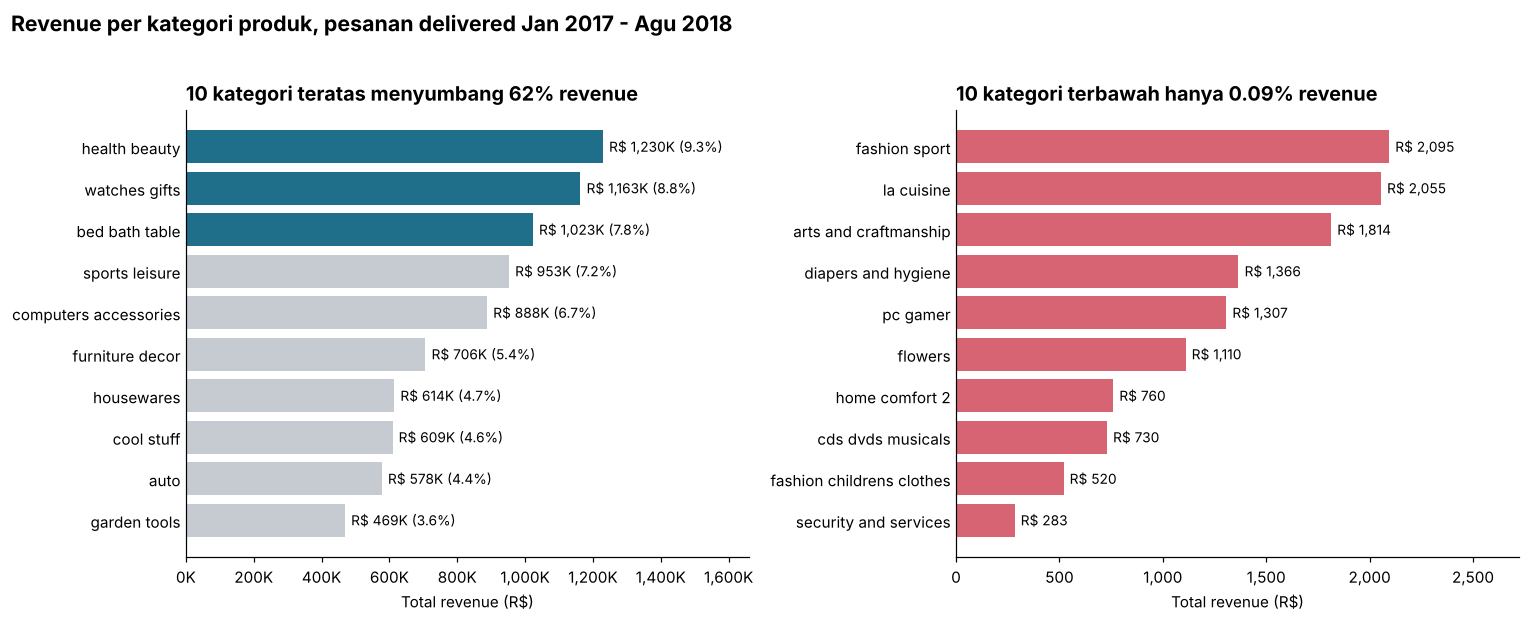

In [27]:
top10 = category_rank.head(10).iloc[::-1]
bottom10 = category_rank.tail(10).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel kiri: top 10 (3 teratas disorot)
warna = [GREY] * 7 + [ACCENT] * 3
bars = axes[0].barh(top10.index.str.replace('_', ' '), top10['revenue'], color=warna)
axes[0].bar_label(bars, labels=[f'R$ {v/1000:,.0f}K ({s:.1f}%)' for v, s in zip(top10['revenue'], top10['share_pct'])], padding=4, fontsize=9)
axes[0].set_title(f'10 kategori teratas menyumbang {top10_share:.0f}% revenue', loc='left')
axes[0].set_xlim(0, top10['revenue'].max() * 1.35)

# Panel kanan: bottom 10
bars = axes[1].barh(bottom10.index.str.replace('_', ' '), bottom10['revenue'], color=ALERT, alpha=0.85)
axes[1].bar_label(bars, labels=[f'R$ {v:,.0f}' for v in bottom10['revenue']], padding=4, fontsize=9)
axes[1].set_title(f'10 kategori terbawah hanya {bottom10_share:.2f}% revenue', loc='left')
axes[1].set_xlim(0, bottom10['revenue'].max() * 1.3)

axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1000:,.0f}K'))
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'))
for ax in axes:
    ax.set_xlabel('Total revenue (R$)')
    ax.tick_params(axis='y', length=0)
fig.suptitle('Revenue per kategori produk, pesanan delivered Jan 2017 - Agu 2018', x=0.01, ha='left', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Insight (Visualisasi Pertanyaan 1):**
- Tiga kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`) menjadi penggerak utama revenue; sepuluh kategori teratas menguasai lebih dari 60% total revenue.
- Ekor panjang di sisi bawah: sepuluh kategori terbawah (mis. `security_and_services`, `fashion_childrens_clothes`) hanya bernilai ratusan hingga ribuan Real, praktis tidak berpengaruh pada pendapatan.

### Pertanyaan 2: Tren pesanan dan revenue bulanan

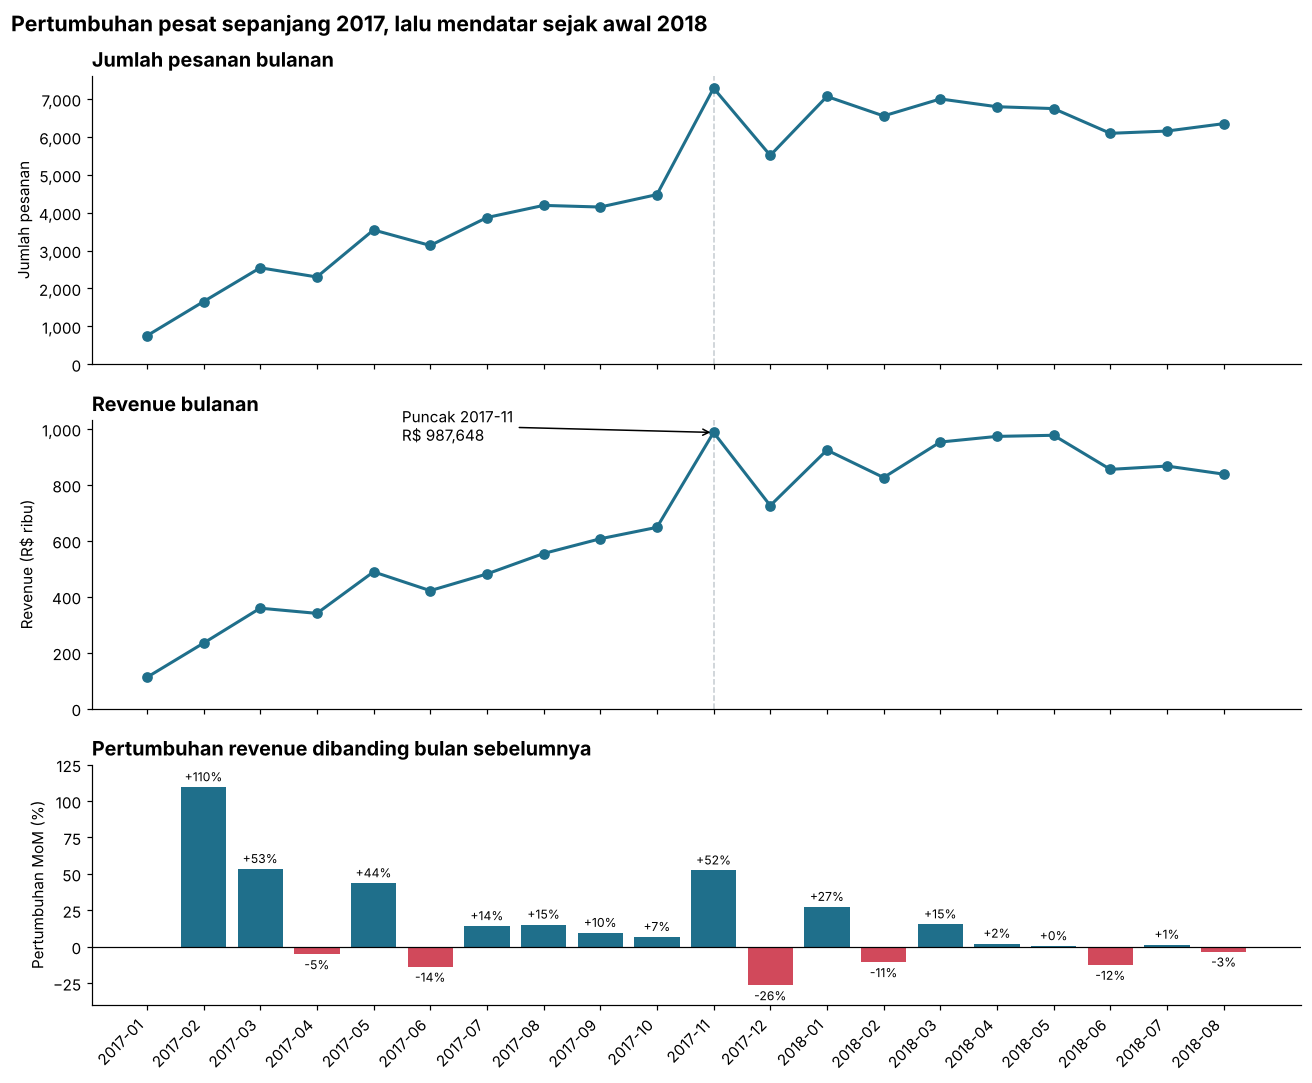

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [1.2, 1.2, 1]})
x = np.arange(len(monthly))
labels = monthly.index

# Panel 1: jumlah pesanan
axes[0].plot(x, monthly['orders'], color=ACCENT, marker='o', linewidth=2)
axes[0].set_ylabel('Jumlah pesanan')
axes[0].set_title('Jumlah pesanan bulanan', loc='left')

# Panel 2: revenue
axes[1].plot(x, monthly['revenue'] / 1000, color=ACCENT, marker='o', linewidth=2)
axes[1].set_ylabel('Revenue (R$ ribu)')
axes[1].set_title('Revenue bulanan', loc='left')
i_peak = list(labels).index(peak_month)
axes[1].annotate(f'Puncak {peak_month}\n{brl(monthly.loc[peak_month, "revenue"])}',
                 xy=(i_peak, monthly.loc[peak_month, 'revenue'] / 1000),
                 xytext=(i_peak - 5.5, monthly['revenue'].max() / 1000 * 0.97),
                 arrowprops=dict(arrowstyle='->', color='black'), fontsize=10)
for ax in axes[:2]:
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.axvline(i_peak, color=GREY, linestyle='--', linewidth=1, zorder=0)

# Panel 3: pertumbuhan MoM revenue
mom = monthly['revenue_mom_pct'].iloc[1:]
warna = [ACCENT if v >= 0 else ALERT for v in mom]
bars = axes[2].bar(x[1:], mom, color=warna)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set_ylabel('Pertumbuhan MoM (%)')
axes[2].set_ylim(-40, 125)
axes[2].set_title('Pertumbuhan revenue dibanding bulan sebelumnya', loc='left')
axes[2].bar_label(bars, labels=[f'{v:+.0f}%' for v in mom], fontsize=8, padding=2)
axes[2].set_xticks(x)
axes[2].set_xticklabels(labels, rotation=45, ha='right')
fig.suptitle('Pertumbuhan pesat sepanjang 2017, lalu mendatar sejak awal 2018', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [29]:
nov_vs_okt = monthly.loc['2017-11', 'revenue'] / monthly.loc['2017-10', 'revenue'] * 100 - 100
des_vs_nov = monthly.loc['2017-12', 'revenue'] / monthly.loc['2017-11', 'revenue'] * 100 - 100
print(f'Nov 2017 vs Okt 2017: {nov_vs_okt:+.1f}% revenue | Des 2017 vs Nov 2017: {des_vs_nov:+.1f}%')

Nov 2017 vs Okt 2017: +52.4% revenue | Des 2017 vs Nov 2017: -26.5%


**Insight (Visualisasi Pertanyaan 2):**
- Puncak revenue dan pesanan terjadi pada **November 2017** (diduga efek *Black Friday*, yang jatuh pada bulan itu), diikuti penurunan pada Desember 2017.
- Tren naik yang kuat sepanjang 2017 berubah menjadi **plateau** pada 2018: pesanan bulanan berkisar 6.000–7.000 dan tidak pernah melampaui puncak November 2017 secara signifikan.
- Pada paruh kedua 2018 pesanan cenderung menurun (Jun–Agu), sinyal bahwa pertumbuhan organik mulai melambat.

### Pertanyaan 3: Keterlambatan pengiriman, review score, dan sebaran per state

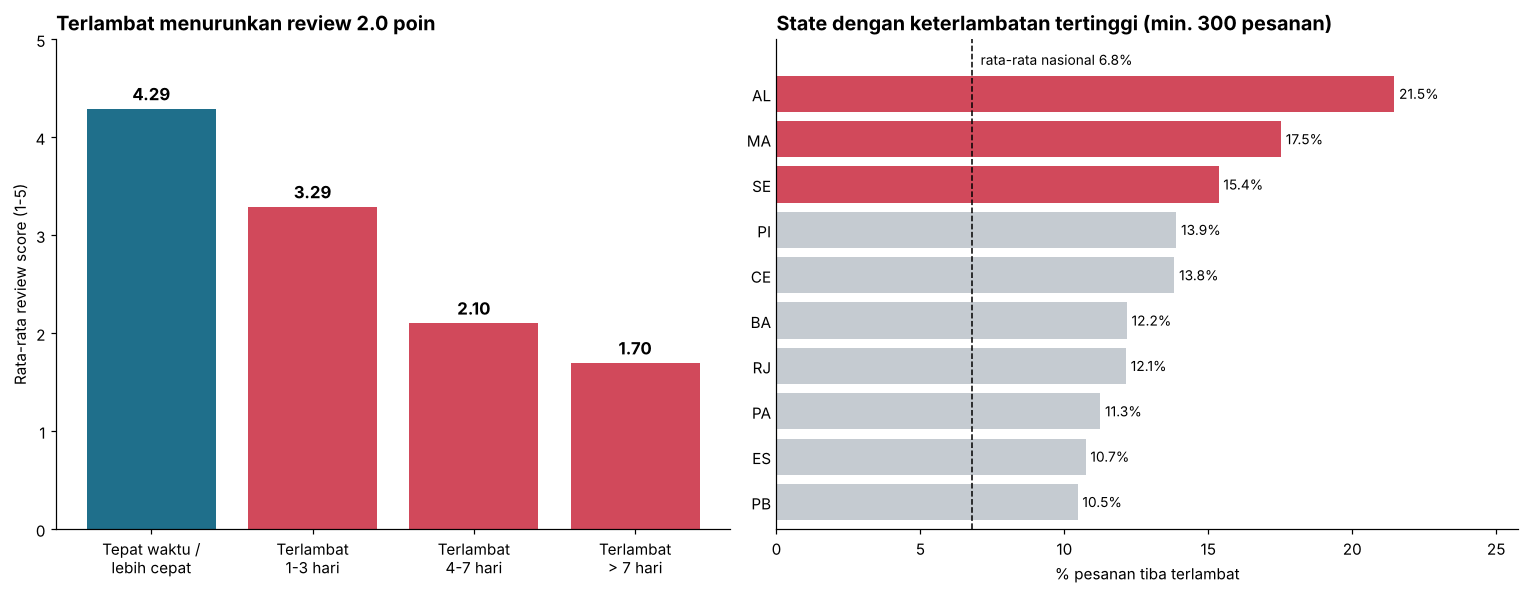

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.1]})

# Panel kiri: review rata-rata per kelompok keterlambatan
warna = [ACCENT] + [ALERT] * 3
bars = axes[0].bar(['Tepat waktu /\nlebih cepat', 'Terlambat\n1-3 hari', 'Terlambat\n4-7 hari', 'Terlambat\n> 7 hari'],
                   delay_stats['avg_review'], color=warna)
axes[0].bar_label(bars, labels=[f'{v:.2f}' for v in delay_stats['avg_review']], padding=3, fontsize=11, fontweight='bold')
axes[0].set_ylim(0, 5)
axes[0].set_ylabel('Rata-rata review score (1-5)')
axes[0].set_title(f'Terlambat menurunkan review {review_gap:.1f} poin', loc='left')

# Panel kanan: 10 state dengan persentase pesanan terlambat tertinggi
top_late = state_rank.head(10).iloc[::-1]
warna = [GREY] * 7 + [ALERT] * 3
bars = axes[1].barh(top_late.index, top_late['late_pct'], color=warna)
axes[1].bar_label(bars, labels=[f'{v:.1f}%' for v in top_late['late_pct']], padding=3, fontsize=9)
axes[1].axvline(late_share, color='black', linestyle='--', linewidth=1)
axes[1].set_ylim(-0.6, 10.2)
axes[1].text(late_share + 0.3, 9.75, f'rata-rata nasional {late_share:.1f}%', fontsize=9, va='center')
axes[1].set_xlim(0, top_late['late_pct'].max() * 1.2)
axes[1].set_xlabel('% pesanan tiba terlambat')
axes[1].set_title('State dengan keterlambatan tertinggi (min. 300 pesanan)', loc='left')
axes[1].tick_params(axis='y', length=0)
plt.tight_layout()
plt.show()

**Insight (Visualisasi Pertanyaan 3):**
- Hubungannya jelas dan bertingkat: pesanan tepat waktu mendapat review sekitar 4,3, sedangkan keterlambatan lebih dari 7 hari turun ke sekitar 1,7, artinya mayoritas pembeli yang menunggu lama memberi nilai sangat buruk.
- Keterlambatan terkonsentrasi secara geografis. **Alagoas (AL), Maranhão (MA), dan Sergipe (SE)** memiliki persentase terlambat tertinggi, jauh di atas rata-rata nasional.
- **Rio de Janeiro (RJ)** menarik perhatian khusus: persentase terlambatnya sekitar 12%, tetapi volume pesanannya terbesar kedua sehingga jumlah pesanan terlambat secara absolut sangat besar.

## Analisis Lanjutan (RFM, Geospatial, dan Binning)

Tiga teknik lanjutan diterapkan tanpa algoritma machine learning:

1. **Geospatial analysis**: memetakan volume pesanan dan persentase keterlambatan tiap state memakai koordinat pelanggan (rata-rata per kode pos). Tujuannya melihat apakah masalah keterlambatan (Pertanyaan 3) membentuk pola wilayah.
2. **Binning / manual grouping**: telah dipakai pada `delay_group` (Pertanyaan 3) dan dipakai lagi untuk pengelompokan recency, frequency, dan monetary pada RFM.
3. **RFM analysis** (Pertanyaan 4): mengelompokkan pelanggan unik berdasarkan *Recency* (hari sejak pembelian terakhir), *Frequency* (jumlah pesanan), dan *Monetary* (total belanja). Tujuannya mengetahui komposisi basis pelanggan dan segmen yang paling bernilai.

### Geospatial Analysis: peta pesanan dan keterlambatan per state

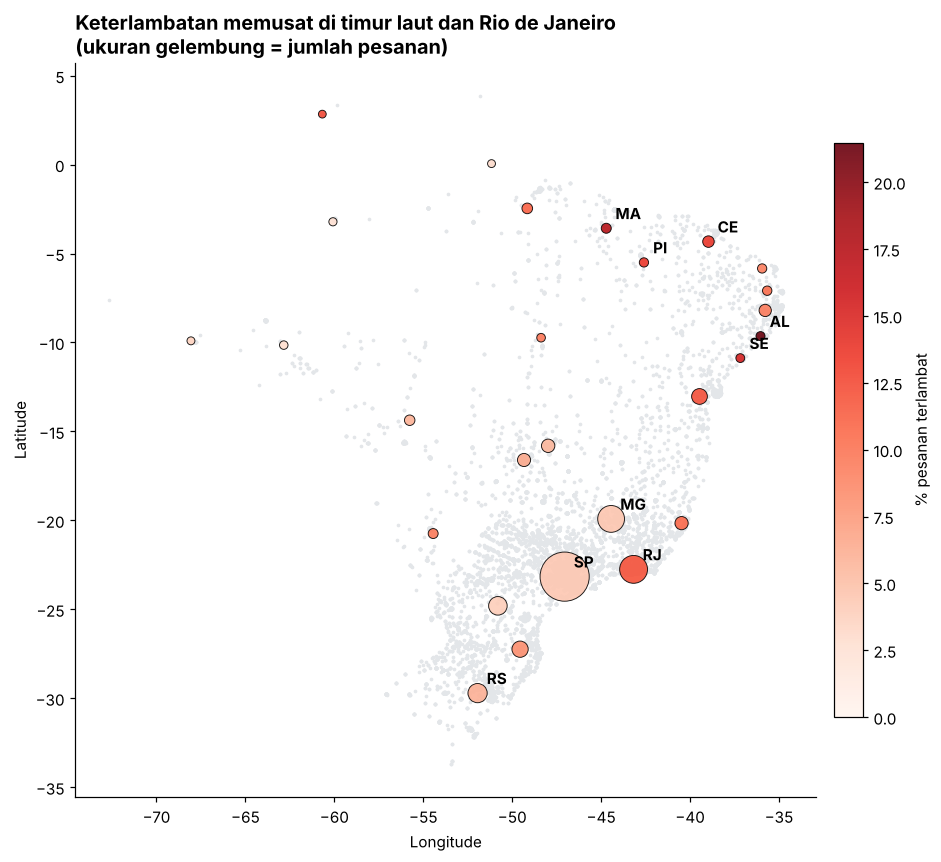

In [31]:
fig, ax = plt.subplots(figsize=(9, 9))

# Latar: sampel titik pelanggan sebagai "siluet" wilayah Brasil
latar = order_df.dropna(subset=['customer_lat']).sample(25000, random_state=42)
ax.scatter(latar['customer_lng'], latar['customer_lat'], s=2, color='#e3e6e9', zorder=1)

# Gelembung: ukuran = jumlah pesanan, warna = % terlambat
sc = ax.scatter(state_stats['lng'], state_stats['lat'], s=state_stats['orders'] / 40 + 25,
                c=state_stats['late_pct'], cmap='Reds', edgecolor='black', linewidth=0.6, alpha=0.9, zorder=2, vmin=0)
cbar = plt.colorbar(sc, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('% pesanan terlambat')

# Label hanya untuk state yang paling relevan agar tidak berdesakan
label_states = set(state_stats.nlargest(4, 'orders').index) | set(state_rank.head(5).index)
for st_code in label_states:
    r = state_stats.loc[st_code]
    ax.annotate(st_code, (r['lng'], r['lat']), xytext=(6, 6), textcoords='offset points', fontsize=10, fontweight='bold')

ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('Keterlambatan memusat di timur laut dan Rio de Janeiro\n(ukuran gelembung = jumlah pesanan)', loc='left')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

In [32]:
# Konsentrasi pelanggan: porsi pesanan dari 3 state teratas dan dari wilayah tenggara (SP, RJ, MG)
share_state = (state_stats['orders'] / state_stats['orders'].sum() * 100).sort_values(ascending=False)
top3_state_share = share_state.head(3).sum()
print(share_state.head(5).round(1).to_string())
print(f'\nTiga state teratas ({", ".join(share_state.head(3).index)}) menyumbang {top3_state_share:.1f}% pesanan')

# Jumlah pesanan terlambat secara absolut per state
late_abs = order_df[order_df['is_late']].groupby('customer_state').size().sort_values(ascending=False)
print('\nJumlah pesanan terlambat terbanyak (absolut):')
print(late_abs.head(5).to_string())

customer_state
SP    42.0
RJ    12.8
MG    11.8
RS     5.5
PR     5.1

Tiga state teratas (SP, RJ, MG) menyumbang 66.6% pesanan

Jumlah pesanan terlambat terbanyak (absolut):
customer_state
SP    1817
RJ    1495
MG     519
BA     396
RS     325


**Insight (Geospatial):**
- Pelanggan sangat terkonsentrasi di tenggara Brasil: tiga state teratas (SP, RJ, MG) menyumbang sekitar dua pertiga pesanan.
- Gelembung merah gelap (keterlambatan tinggi) berada di sepanjang timur laut (AL, MA, SE, CE, BA), jauh dari kluster pelanggan di tenggara. Dugaan bahwa penyebabnya adalah jarak ke pusat penjual belum diuji di sini karena data seller tidak dipakai. Sebaliknya, São Paulo, Minas Gerais, dan Paraná termasuk state dengan keterlambatan terendah di antara state besar.
- Dalam jumlah absolut, **SP dan RJ** memiliki pesanan terlambat terbanyak, sehingga perbaikan logistik tetap perlu menyasar dua state besar ini selain state timur laut yang persentasenya tinggi.

### RFM Analysis (Pertanyaan 4)

**Cara kerja.**
- *Snapshot date* = 1 September 2018 (sehari setelah akhir periode analisis, 31 Agustus 2018).
- *Recency* = jumlah hari dari pembelian terakhir sampai snapshot. *Frequency* = jumlah pesanan unik. *Monetary* = total `price` seluruh pesanannya.
- Skor kuintil klasik tidak cocok di sini karena **hampir semua pelanggan hanya membeli sekali** (frequency = 1), sehingga batas kuintil akan berimpit. Maka dipakai **binning berbasis aturan bisnis**: recency dikelompokkan ke rentang hari yang bermakna, frequency dibagi 1 vs 2+, dan monetary dibagi tiga tingkat berdasarkan persentil (rendah, menengah, tinggi).

In [33]:
snapshot_date = pd.Timestamp('2018-09-01')   # sehari setelah akhir periode analisis (31 Agustus 2018)
print('Snapshot date:', snapshot_date.date())

rfm = (all_df.groupby('customer_unique_id')
       .agg(last_purchase=('order_purchase_timestamp', 'max'),
            frequency=('order_id', 'nunique'),
            monetary=('price', 'sum'))
       .reset_index())
rfm['recency'] = (snapshot_date - rfm['last_purchase'].dt.normalize()).dt.days
rfm = rfm.drop(columns='last_purchase')

print(f'Jumlah pelanggan unik: {len(rfm):,}')
print(f'Pelanggan dengan 1 pesanan: {(rfm["frequency"] == 1).mean():.1%} | 2+ pesanan: {(rfm["frequency"] >= 2).mean():.1%}')
rfm[['recency', 'frequency', 'monetary']].describe().round(1)

Snapshot date: 2018-09-01
Jumlah pelanggan unik: 93,096
Pelanggan dengan 1 pesanan: 97.0% | 2+ pesanan: 3.0%


,recency,frequency,monetary
count,93096.0,93096.0,93096.0
mean,239.2,1.0,141.6
std,150.9,0.2,215.8
min,3.0,1.0,0.8
25%,117.0,1.0,47.6
50%,221.0,1.0,89.7
75%,348.0,1.0,154.2
max,604.0,15.0,13440.0


In [34]:
# Binning
rfm['recency_group'] = pd.cut(rfm['recency'], bins=[0, 90, 180, 365, np.inf],
                              labels=['0-90 hari', '91-180 hari', '181-365 hari', '> 365 hari'])
rfm['monetary_tier'] = pd.qcut(rfm['monetary'].rank(method='first'), q=[0, 0.5, 0.9, 1],
                               labels=['Rendah (50% bawah)', 'Menengah', 'Tinggi (10% teratas)'])

# Aturan segmentasi (manual grouping)
kondisi = [
    (rfm['frequency'] >= 2) & (rfm['recency'] <= 180),
    (rfm['frequency'] >= 2) & (rfm['recency'] > 180),
    (rfm['frequency'] == 1) & (rfm['recency'] <= 180) & (rfm['monetary_tier'] == 'Tinggi (10% teratas)'),
    (rfm['frequency'] == 1) & (rfm['recency'] <= 180),
    (rfm['frequency'] == 1) & (rfm['recency'] > 180) & (rfm['monetary_tier'] == 'Tinggi (10% teratas)'),
]
nama_segmen = ['Champions (repeat, aktif)', 'Repeat - Dormant', 'New High Spender',
               'Pelanggan Baru', 'Lapsed High Value']
rfm['segment'] = np.select(kondisi, nama_segmen, default='Lapsed (satu kali beli, lama pergi)')

urutan = nama_segmen + ['Lapsed (satu kali beli, lama pergi)']
segment_stats = (rfm.groupby('segment')
                 .agg(customers=('customer_unique_id', 'count'), revenue=('monetary', 'sum'),
                      avg_recency=('recency', 'mean'), avg_monetary=('monetary', 'mean'))
                 .reindex(urutan))
segment_stats['customer_pct'] = segment_stats['customers'] / segment_stats['customers'].sum() * 100
segment_stats['revenue_pct'] = segment_stats['revenue'] / segment_stats['revenue'].sum() * 100
segment_stats.round(1)

,customers,revenue,avg_recency,avg_monetary,customer_pct,revenue_pct
segment,,,,,,
"Champions (repeat, aktif)",1210,326871.9,91.9,270.1,1.3,2.5
Repeat - Dormant,1579,398483.2,321.9,252.4,1.7,3.0
New High Spender,3460,2072292.1,95.9,598.9,3.7,15.7
Pelanggan Baru,32883,3028952.4,93.2,92.1,35.3,23.0
Lapsed High Value,5050,2909733.8,344.3,576.2,5.4,22.1
"Lapsed (satu kali beli, lama pergi)",48914,4443444.6,337.7,90.8,52.5,33.7


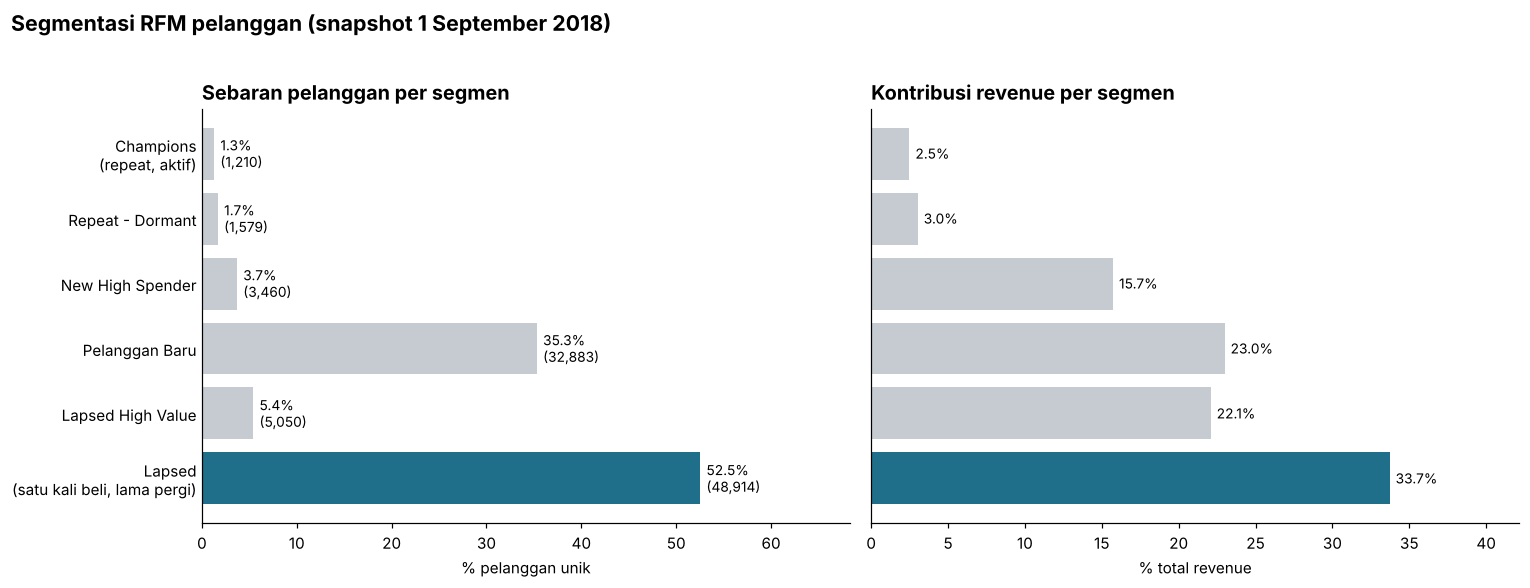

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
seg = segment_stats.iloc[::-1]
label_y = [s.replace(' (', '\n(') for s in seg.index]

top_rev = seg['revenue_pct'].idxmax()
warna_rev = [ACCENT if s == top_rev else GREY for s in seg.index]
warna_cus = [ACCENT if s == seg['customer_pct'].idxmax() else GREY for s in seg.index]

bars = axes[0].barh(label_y, seg['customer_pct'], color=warna_cus)
axes[0].bar_label(bars, labels=[f'{v:.1f}%\n({c:,.0f})' for v, c in zip(seg['customer_pct'], seg['customers'])], padding=4, fontsize=9)
axes[0].set_xlim(0, seg['customer_pct'].max() * 1.3)
axes[0].set_title('Sebaran pelanggan per segmen', loc='left')
axes[0].set_xlabel('% pelanggan unik')

bars = axes[1].barh(label_y, seg['revenue_pct'], color=warna_rev)
axes[1].bar_label(bars, labels=[f'{v:.1f}%' for v in seg['revenue_pct']], padding=4, fontsize=9)
axes[1].set_xlim(0, seg['revenue_pct'].max() * 1.25)
axes[1].set_title('Kontribusi revenue per segmen', loc='left')
axes[1].set_xlabel('% total revenue')
for ax in axes:
    ax.tick_params(axis='y', length=0)
fig.suptitle('Segmentasi RFM pelanggan (snapshot 1 September 2018)', x=0.01, ha='left', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Insight (RFM):** basis pelanggan sangat timpang ke pembeli satu kali: 97,0% pelanggan hanya bertransaksi sekali. Segmen *repeat* (Champions + Repeat - Dormant) hanya 3,0% dari pelanggan. Batang berwarna aksen menandai segmen terbesar pada masing-masing panel. Segmen *Lapsed High Value* kecil dalam jumlah (5,4% pelanggan) tetapi besar dalam nilai (22,1% revenue), sehingga layak diprioritaskan untuk reaktivasi.

## Conclusion

### Conclusion Pertanyaan 1: kategori produk
- Sepuluh kategori teratas menyumbang **62,5%** dari total revenue R$ 13.179.778. Tiga teratas, yaitu `health_beauty`, `watches_gifts`, `bed_bath_table`, menyumbang **25,9%** sendiri.
- Kategori nomor satu, `health_beauty`, bernilai R$ 1.229.558 (9,3% dari total).
- Sepuluh kategori terbawah hanya menyumbang **0,09%** revenue; yang terendah adalah `security_and_services` dengan R$ 283.
- Peringkat revenue tidak identik dengan peringkat volume: nilai per item ikut menentukan kontribusi.

### Conclusion Pertanyaan 2: tren bulanan
- Revenue bulanan tumbuh dari R$ 111.798 (Jan 2017) hingga puncaknya **R$ 987.648 pada 2017-11** (7.288 pesanan).
- Pertumbuhan MoM tertinggi pada basis yang sudah matang (revenue bulan sebelumnya minimal R$ 300 ribu) terjadi pada **2017-11 (52,4%)**, sedangkan penurunan terdalam terjadi pada **2017-12 (-26,5%)**, tepat setelah lonjakan.
- Dibanding periode Jan–Agu 2017, revenue Jan–Agu 2018 naik **141,1%**, namun sepanjang 2018 revenue relatif mendatar (sekitar R$ 0,83–0,98 juta per bulan) dan pesanan Jun–Agu 2018 lebih rendah dari Jan–Mei 2018.

### Conclusion Pertanyaan 3: keterlambatan dan kepuasan pelanggan
- Pesanan tepat waktu mendapat review rata-rata **4,29**, sedangkan pesanan terlambat hanya **2,27**, selisih **2,02 poin**. Skor turun makin dalam seiring lamanya keterlambatan (di atas 7 hari rata-rata 1,70).
- Secara nasional **6,8%** pesanan tiba terlambat. State dengan persentase tertinggi (min. 300 pesanan): **AL (21,5%), MA (17,5%), SE (15,4%)**.
- RJ memiliki 12,1% pesanan terlambat dengan volume 12.310 pesanan, sehingga dampaknya paling besar secara absolut setelah SP.

### Conclusion Pertanyaan 4: segmentasi RFM
- Dari **93.096 pelanggan unik**, **97,0%** hanya membeli satu kali. Pelanggan repeat (Champions + Repeat - Dormant) hanya **3,0%** dari pelanggan namun menyumbang **5,5%** revenue.
- Segmen penyumbang revenue terbesar adalah **Lapsed (satu kali beli, lama pergi)** (33,7% revenue dari 52,5% pelanggan).
- Segmen *Lapsed* (pembeli satu kali yang sudah lebih dari 180 hari tidak kembali) berukuran 52,5% pelanggan, ditambah *Lapsed High Value* sebanyak 5.050 pelanggan (22,1% revenue) yang bernilai tinggi dan layak diprioritaskan untuk reaktivasi.

### Rekomendasi (Action Item)
1. **Prioritaskan stok, promosi, dan rekrutmen seller pada kategori teratas** (`health_beauty`, `watches_gifts`, `bed_bath_table`) karena menyumbang 25,9% revenue. Evaluasi kategori ekor (bottom 10) untuk digabung, dipromosikan ulang, atau dikurangi fokusnya.
2. **Siapkan kampanye musiman dan kapasitas operasional sebelum November.** Lonjakan November 2017 menunjukkan potensi besar Black Friday, namun penurunan Desember dan plateau 2018 menunjukkan perlunya kampanye baru (mis. promo tengah tahun) untuk mendorong pertumbuhan.
3. **Perbaiki logistik di wilayah dengan keterlambatan tertinggi** (AL, MA, SE) lewat opsi pusat distribusi/kurir lokal atau estimasi tiba yang lebih realistis, serta **audit performa pengiriman di RJ dan SP** karena volume terbesar. Pesanan yang tiba tepat waktu berasosiasi dengan review sekitar 2,0 poin lebih tinggi (asosiasi, bukan bukti sebab-akibat).
4. **Bangun program retensi.** Mayoritas pelanggan tidak pernah kembali; jalankan voucher pembelian kedua dalam 30–60 hari setelah pembelian pertama, dan kampanye reaktivasi khusus untuk segmen *Lapsed High Value* dan *Repeat - Dormant*.

*Keterbatasan:* analisis memakai pesanan *delivered* saja, revenue dihitung dari harga produk tanpa ongkir, hubungan keterlambatan dan review bersifat asosiasi (bukan bukti sebab-akibat), dan pelanggan yang membeli satu kali pada periode pendek 20 bulan belum tentu benar-benar berhenti berbelanja.